# CineScore - Exploratory Data Analysis
Dataset: `data/processed/features.parquet`, built by `scripts/01`-`04` from the official IMDb
non-commercial datasets and the TMDB API. One row per film; target = `averageRating` (IMDb, 1-10).

Covered here: target distribution, missing values, outliers, correlations, and the regression
equivalent of class balance (how ratings are spread across rating bands and groups).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
from cinescore_style import ACCENT, BOX, GREY, INK, LIGHT, MUTED, apply_style, title

apply_style()  # one shared chart style (same colours as the web apps), see cinescore_style.py

df = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
print(df.shape)
df.head()


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

(27451, 61)


## 1. Target distribution

count    27451.00
mean         6.26
std          1.12
min          1.00
25%          5.60
50%          6.40
75%          7.10
max          9.40
Name: averageRating, dtype: float64
skew: -0.751


findfont: Failed to find font weight semibold for Georgia, now using 700.


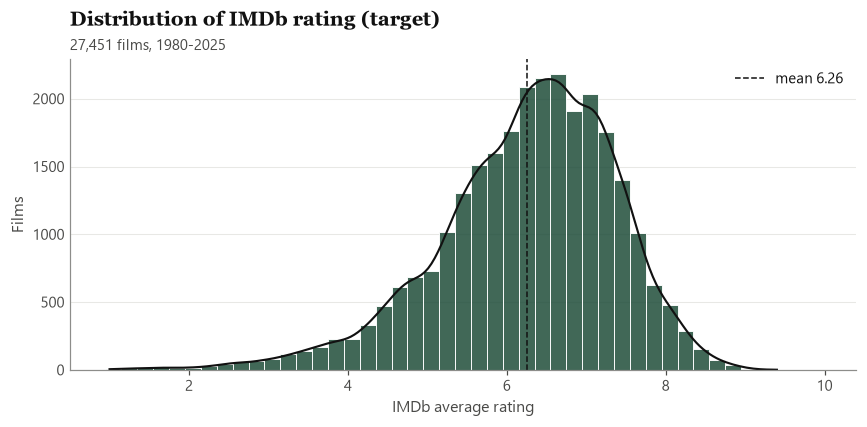

In [2]:
print(df.averageRating.describe().round(2))
print("skew:", round(df.averageRating.skew(), 3))
fig, ax = plt.subplots(figsize=(8, 4))
# 0.2-wide bins aligned to the one-decimal ratings (equal-width bins would catch 2 or 3 values unevenly)
sns.histplot(df.averageRating, bins=np.arange(0.95, 10.05, 0.2), kde=True, ax=ax, color=ACCENT, alpha=.85)
ax.lines[0].set(color=INK, linewidth=1.4)  # density curve in ink
ax.axvline(df.averageRating.mean(), color=INK, ls="--", lw=1, label=f"mean {df.averageRating.mean():.2f}")
title(ax, "Distribution of IMDb rating (target)", f"{len(df):,} films, 1980-2025")
ax.set(xlabel="IMDb average rating", ylabel="Films")
ax.legend()
save("01_target_distribution")

The target is roughly bell-shaped and slightly left-skewed (a tail of very poorly rated films).
A model that always predicts the mean is our baseline.

**"Class balance" for regression** - share of films in each rating band:

averageRating
<4      4.0
4-5     9.3
5-6    24.1
6-7    37.5
7-8    22.3
8+      2.8
Name: proportion, dtype: float64


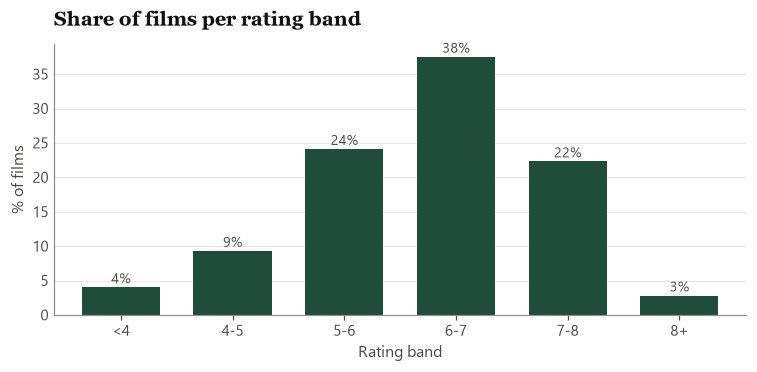

In [3]:
bands = pd.cut(df.averageRating, [0, 4, 5, 6, 7, 8, 10],
               labels=["<4", "4-5", "5-6", "6-7", "7-8", "8+"])
bal = bands.value_counts(normalize=True).sort_index().mul(100).round(1)
print(bal)
fig, ax = plt.subplots(figsize=(7, 3.5))
bal.plot.bar(ax=ax, color=ACCENT, width=.7)
ax.grid(axis="x", visible=False)
for i, v in enumerate(bal):
    ax.text(i, v + 0.6, f"{v:.0f}%", ha="center", fontsize=9, color=MUTED)
title(ax, "Share of films per rating band")
ax.set(xlabel="Rating band", ylabel="% of films")
ax.tick_params(axis="x", rotation=0)
save("02_rating_bands")

Extreme bands (<4 and 8+) are rare, so we expect larger errors there - a model trained on this
distribution will pull extreme films toward the middle.

## 2. Missing values

franchise_prev_mean    92.7
log_budget             58.5
us_certification       40.3
director_prev_mean     26.8
writer_prev_mean       23.9
cast_prev_mean         18.3
female_lead             3.0
main_country            1.4
release_month           0.6
release_dow             0.6
dtype: float64


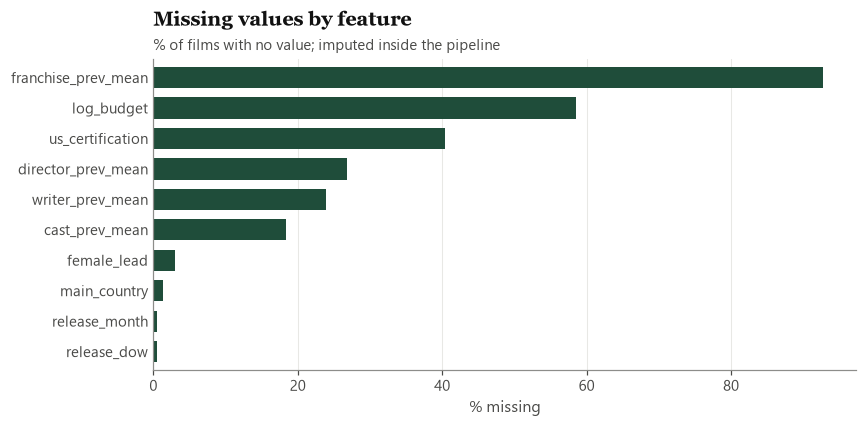

In [4]:
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(1))
fig, ax = plt.subplots(figsize=(8, 4))
miss.plot.barh(ax=ax, color=ACCENT, width=.7)
ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
title(ax, "Missing values by feature", "% of films with no value; imputed inside the pipeline")
ax.set(xlabel="% missing")
save("03_missing_values")

* `franchise_prev_mean` is missing for most films because most films are not in a franchise
  (or are the first entry) - a structural gap, not a data error.
* `log_budget` is missing for ~59% of films (TMDB budget unknown); `budget_known` flags this.
* Track-record means are missing for debut directors/writers/casts; their `_prev_count` is 0.

All imputation (median + missing-indicator) happens inside the scikit-learn Pipeline, fitted on
the training split only.

## 3. Outliers

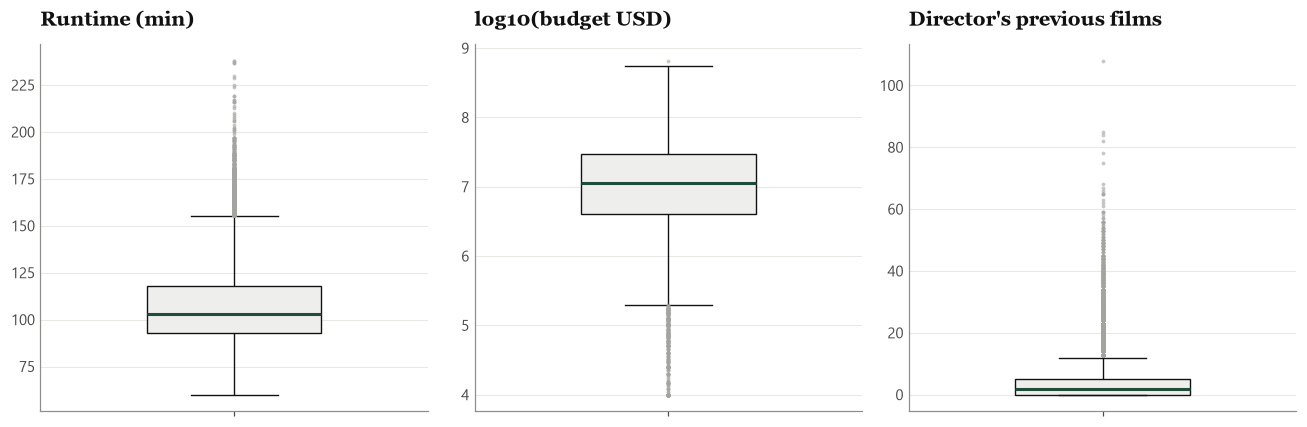

runtime                IQR outliers:  1050 (3.8%)
log_budget             IQR outliers:   310 (2.7%)
director_prev_count    IQR outliers:  2234 (8.1%)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, lab in zip(axes, ["runtime", "log_budget", "director_prev_count"],
                        ["Runtime (min)", "log10(budget USD)", "Director's previous films"]):
    sns.boxplot(y=df[col], ax=ax, width=.45, **BOX)
    title(ax, lab)
    ax.set(ylabel="")
save("04_outliers_boxplots")

for col in ["runtime", "log_budget", "director_prev_count"]:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:22s} IQR outliers: {n:5d} ({n / df[col].notna().sum():.1%})")

Outliers are genuine (3-4 hour epics, US$300M blockbusters, prolific directors), not errors,
so they are kept. Runtime was already restricted to 60-240 min and budgets below US$10k (junk
entries) were set to missing in the feature script. Tree models are robust to them; for linear
and KNN models the features are standardised inside the Pipeline.

## 4. Correlations

franchise_prev_mean    0.716
director_prev_mean     0.537
writer_prev_mean       0.501
cast_prev_mean         0.475
genre_horror          -0.310
runtime                0.304
genre_drama            0.251
genre_documentary      0.203
us_production         -0.193
genre_biography        0.155
genre_thriller        -0.149
genre_sci_fi          -0.123
genre_action          -0.115
genre_history          0.111
n_spoken_languages     0.110
Name: averageRating, dtype: float64


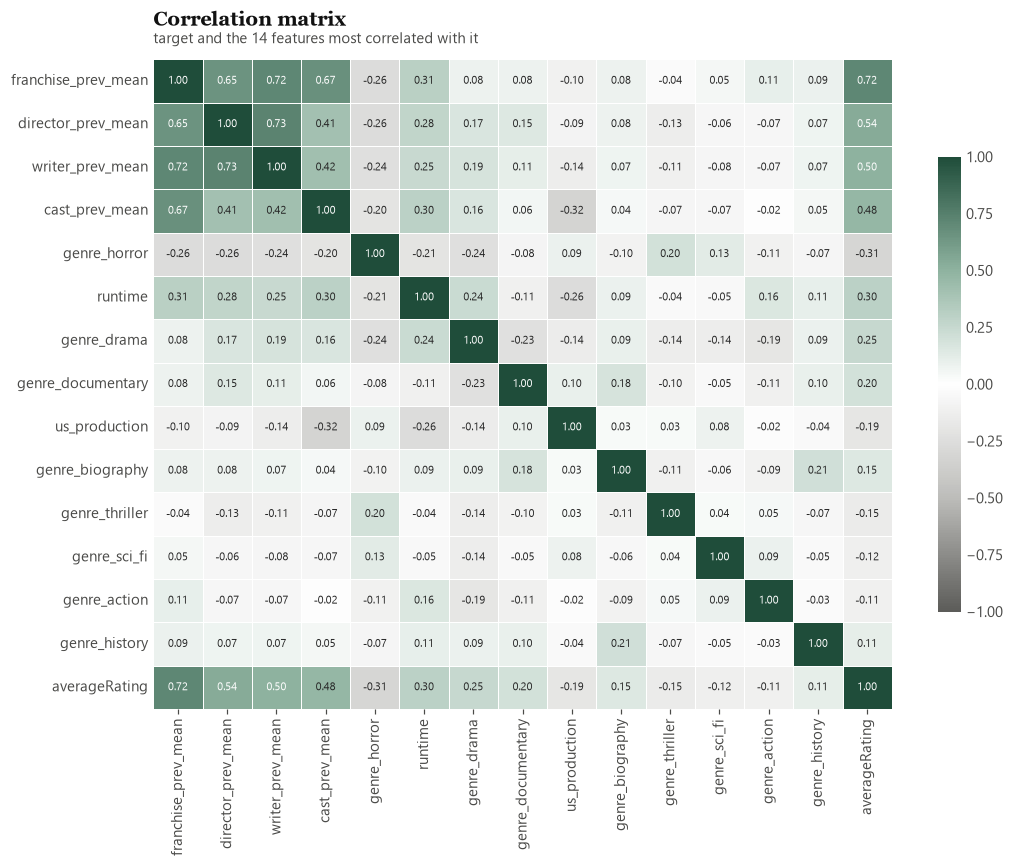

In [6]:
num = df.select_dtypes("number")
corr_t = num.corr()["averageRating"].drop("averageRating").sort_values(key=abs, ascending=False)
print(corr_t.head(15).round(3))

top = corr_t.abs().head(14).index.tolist() + ["averageRating"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num[top].corr(), cmap="cinescore_div", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, linecolor="white", ax=ax, cbar_kws={"shrink": .7})
ax.grid(False)
title(ax, "Correlation matrix", "target and the 14 features most correlated with it")
save("05_correlation_heatmap")

Track-record features dominate: the mean rating of a film's franchise, director, writers and
lead cast in earlier years. Director and writer track records are correlated with each other
(often the same person), which matters for linear models (Ridge regularisation helps).

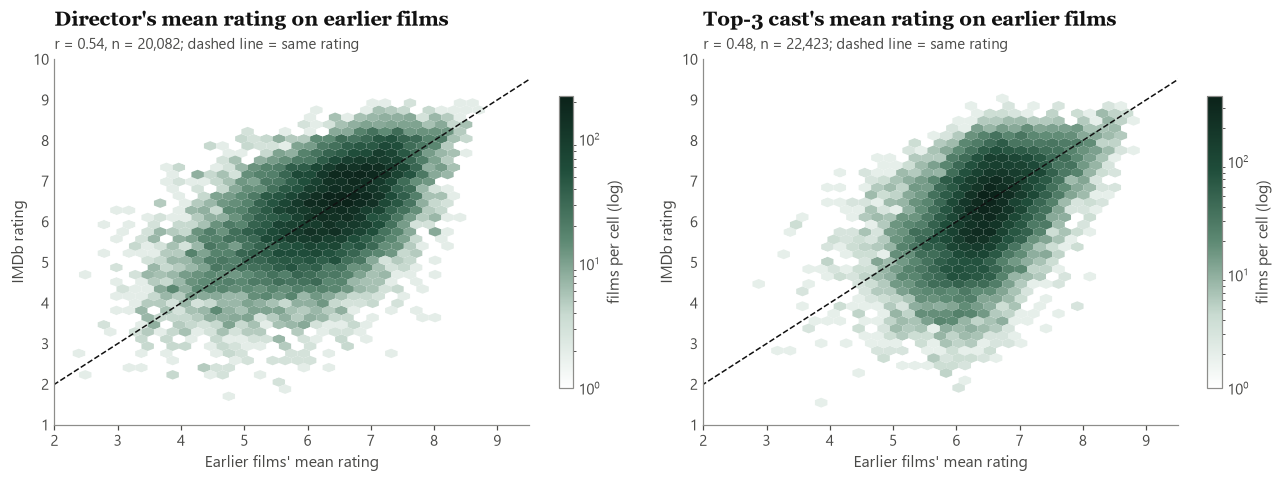

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, lab in zip(axes, ["director_prev_mean", "cast_prev_mean"],
                        ["Director's mean rating on earlier films", "Top-3 cast's mean rating on earlier films"]):
    sub = df[[col, "averageRating"]].dropna()
    hb = ax.hexbin(sub[col], sub.averageRating, gridsize=40, cmap="cinescore", mincnt=1, bins="log",
                   linewidths=0)
    ax.plot([1, 10], [1, 10], color=INK, ls="--", lw=1)
    ax.grid(False)
    fig.colorbar(hb, ax=ax, shrink=.8, label="films per cell (log)")
    title(ax, lab, f"r = {sub.corr().iloc[0, 1]:.2f}, n = {len(sub):,}; dashed line = same rating")
    ax.set(xlim=(2, 9.5), ylim=(1, 10), xlabel="Earlier films' mean rating", ylabel="IMDb rating")
save("06_track_record_vs_rating")

## 5. Rating by genre, certification and year

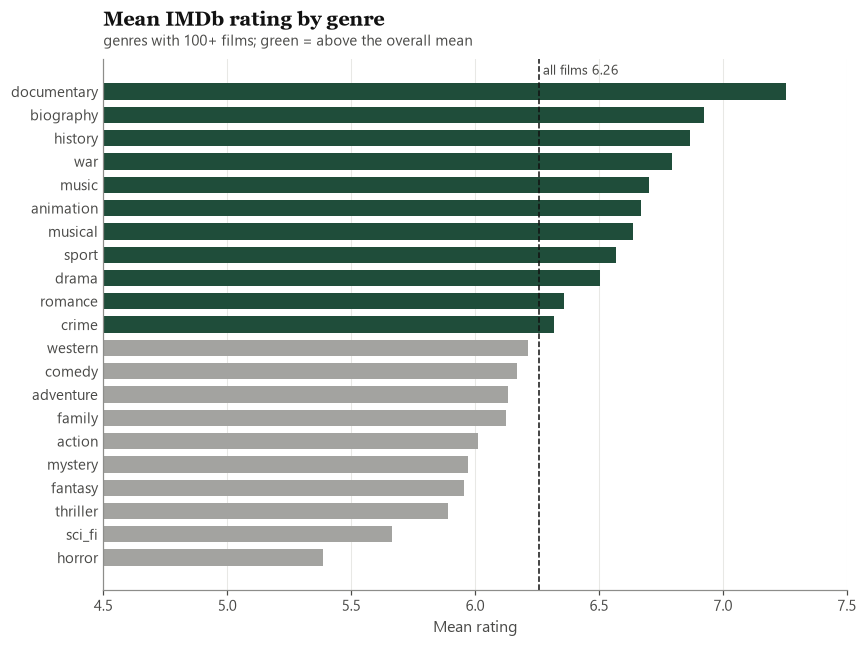

In [8]:
gcols = [c for c in df if c.startswith("genre_")]
g = pd.DataFrame({
    "genre": [c.replace("genre_", "") for c in gcols],
    "mean_rating": [df.loc[df[c] == 1, "averageRating"].mean() for c in gcols],
    "films": [int(df[c].sum()) for c in gcols],
}).query("films >= 100").sort_values("mean_rating")
fig, ax = plt.subplots(figsize=(8, 6))
overall = df.averageRating.mean()
ax.barh(g.genre, g.mean_rating, color=[ACCENT if v >= overall else GREY for v in g.mean_rating], height=.7)
ax.axvline(overall, color=INK, ls="--", lw=1)
ax.text(overall, len(g) - 0.4, f" all films {overall:.2f}", fontsize=9, color=MUTED, va="bottom")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
title(ax, "Mean IMDb rating by genre", "genres with 100+ films; green = above the overall mean")
ax.set(xlim=(4.5, 7.5), xlabel="Mean rating")
save("07_rating_by_genre")

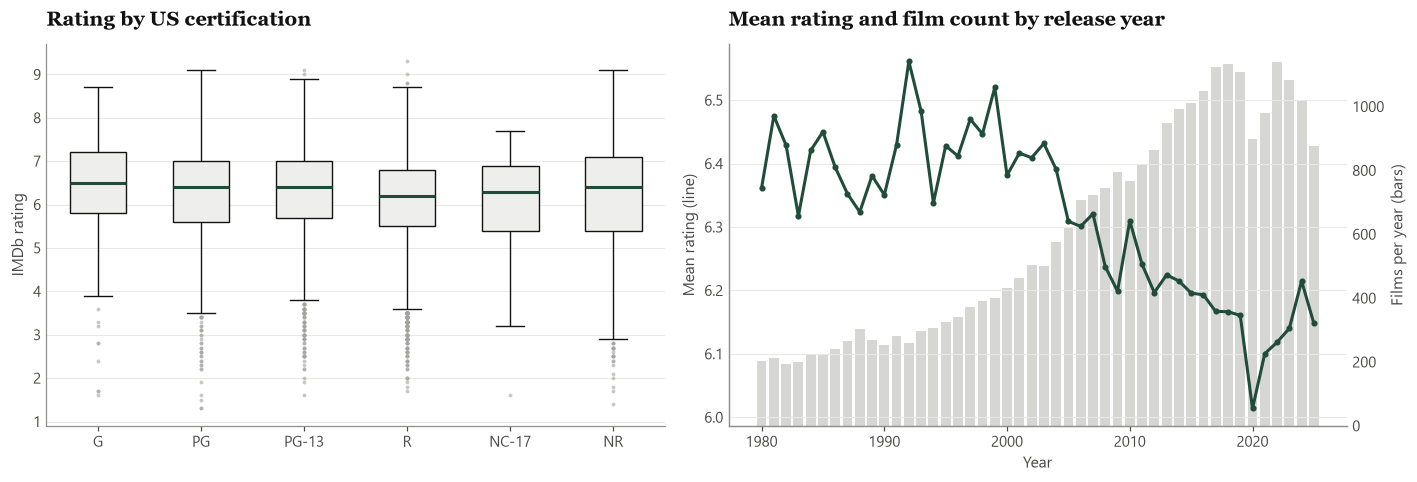

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cert_order = ["G", "PG", "PG-13", "R", "NC-17", "NR"]
c = df[df.us_certification.isin(cert_order)]
sns.boxplot(data=c, x="us_certification", y="averageRating", order=cert_order, ax=axes[0], width=.55, **BOX)
title(axes[0], "Rating by US certification")
axes[0].set(xlabel="", ylabel="IMDb rating")
yr = df.groupby("year").averageRating.agg(["mean", "count"])
ax2 = axes[1].twinx()
ax2.bar(yr.index, yr["count"], color=LIGHT, width=.8)
ax2.set_ylabel("Films per year (bars)", color=MUTED)
ax2.grid(False)
axes[1].set_zorder(ax2.get_zorder() + 1); axes[1].patch.set_visible(False)
axes[1].plot(yr.index, yr["mean"], color=ACCENT, marker="o", ms=3)
title(axes[1], "Mean rating and film count by release year")
axes[1].set(xlabel="Year", ylabel="Mean rating (line)")
save("08_certification_and_year")

## Key findings
1. Target is near-normal (mean ~6.26, sd ~1.12); extremes are rare -> expect regression to the mean.
2. Missingness is structural (no franchise, unknown budget, debut talent); handled in-pipeline
   with median imputation plus missing indicators.
3. Outliers are genuine and kept; scaling is applied for distance/linear models.
4. Track-record features are the strongest predictors (|r| 0.47-0.72); horror (negative),
   documentary, drama and biography (positive) and runtime (positive) also matter.
5. The film mix changes over time (more films per year recently), so we use a **time-ordered**
   train/validation/test split to mimic predicting future releases.